<a href="https://colab.research.google.com/github/SachinCyprus/Youtube-comments-analysic-DA-/blob/main/youtube_comments_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

✅ Dataset Loaded Successfully!
Shape: (300, 5)
Columns: ['AUTHOR', 'CONTENT', 'DATE', 'TIME', 'LIKES']
   AUTHOR                     CONTENT       DATE      TIME  LIKES
0  User_1    I’m not sure about this.  4/19/2023  19:44:49    102
1  User_2            Could be better.   2/3/2023  19:41:11    435
2  User_3  I didn’t like the editing.  6/14/2023  14:41:44    348
3  User_4           Nice explanation!   5/4/2023   6:36:07    270
4  User_5            This was boring.  6/18/2023  22:44:14    106

🧹 Text Cleaning Completed!
                      CONTENT              Cleaned_Text
0    I’m not sure about this.    im not sure about this
1            Could be better.           could be better
2  I didn’t like the editing.  i didnt like the editing
3           Nice explanation!          nice explanation
4            This was boring.           this was boring

✅ Sentiment labeling done using TextBlob.
Sentiment
Positive    147
Negative    111
Neutral      42
Name: count, dtype: int64

Train sha

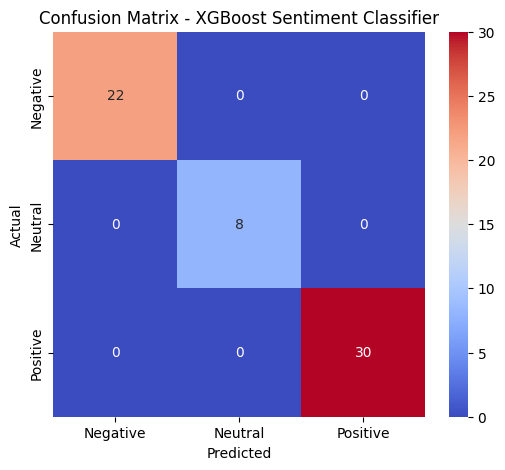


🔍 Example Predictions:
                      CONTENT Predicted_Sentiment
0    I’m not sure about this.            Negative
1            Could be better.            Positive
2  I didn’t like the editing.             Neutral
3           Nice explanation!            Positive
4            This was boring.            Negative
5  I didn’t like the editing.             Neutral
6            This was boring.            Negative
7    I’m not sure about this.            Negative
8                   Loved it!            Positive
9            Could be better.            Positive


/tmp/ipython-input-78272429.py:130: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Predicted_Sentiment", data=df, palette="coolwarm")


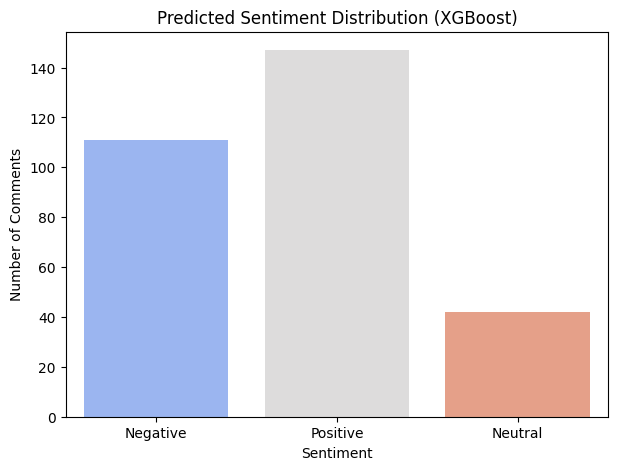

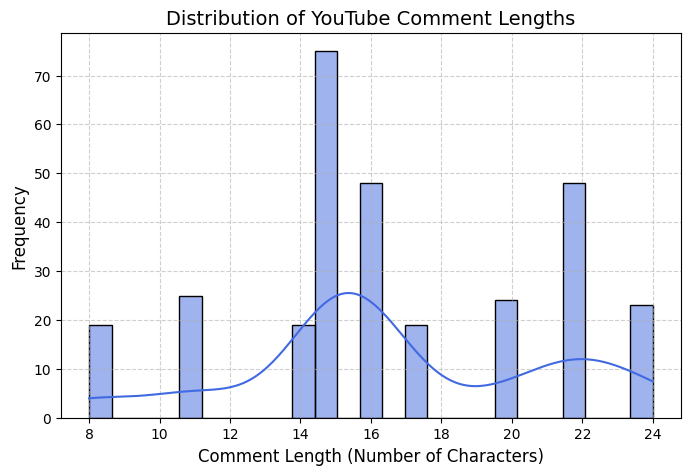

<Figure size 1000x600 with 0 Axes>

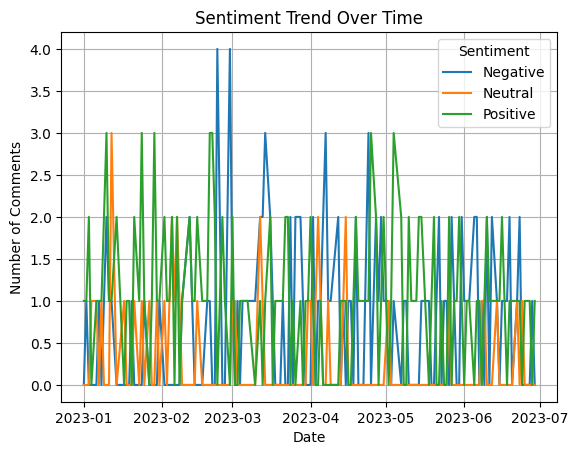


💾 Saved analyzed data as 'YouTube_XGBoost_Sentiment_Predictions.csv'
✅ Project Executed Successfully!


In [ ]:
# %%
# 1️⃣ IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from xgboost import XGBClassifier


# %%
# 2️⃣ LOAD DATA

file_path = ("YouTube_Comments_300 - Copy.csv")   # update path if needed

df = pd.read_csv("YouTube_Comments_300 - Copy.csv")
print("✅ Dataset Loaded Successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

# %%
# 3️⃣ DATA CLEANING

def clean_text(text):
    if pd.isnull(text):
        return ""
    text = str(text)
    text = re.sub(r"http\S+|www\S+", "", text)      # remove URLs
    text = text.encode('ascii', 'ignore').decode('ascii')  # remove emojis
    text = re.sub(r"[^\w\s]", "", text)             # remove punctuation
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

# Detect text column automatically
text_col = None
for c in df.columns:
    if "comment" in c.lower() or "content" in c.lower() or "text" in c.lower():
        text_col = c
        break

if not text_col:
    raise ValueError("No column found containing comments! Please rename it to include 'comment' or 'text'.")

df["Cleaned_Text"] = df[text_col].apply(clean_text)
print("\n🧹 Text Cleaning Completed!")
print(df[[text_col, "Cleaned_Text"]].head())

# %%
# 4️⃣ SENTIMENT LABELING (using TextBlob for training data)

from textblob import TextBlob

def get_sentiment_label(text):
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    else:
        return "Neutral"

df["Sentiment"] = df["Cleaned_Text"].apply(get_sentiment_label)
print("\n✅ Sentiment labeling done using TextBlob.")
print(df["Sentiment"].value_counts())

# %%
# 5️⃣ FEATURE EXTRACTION (TF-IDF)

tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1,2))
X = tfidf.fit_transform(df["Cleaned_Text"])

# Encode target labels
le = LabelEncoder()
y = le.fit_transform(df["Sentiment"])

# %%
# 6️⃣ TRAIN-TEST SPLIT
# ===================================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("\nTrain shape:", X_train.shape, " | Test shape:", X_test.shape)

# %%
# 7️⃣ TRAIN XGBOOST MODEL

model = XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6
)
model.fit(X_train, y_train)

# %%
# 8️⃣ EVALUATION

y_pred = model.predict(X_test)
print("\n🎯 XGBoost Model Evaluation:")
print("Accuracy:", round(accuracy_score(y_test, y_pred)*100, 2), "%")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=le.classes_))

# Confusion Matrix
plt.figure(figsize=(6,5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='coolwarm',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBoost Sentiment Classifier")
plt.show()

# %%
# 9️⃣ PREDICT ON ALL COMMENTS (automatic analysis)

df["Predicted_Sentiment"] = le.inverse_transform(model.predict(X))
print("\n🔍 Example Predictions:")
print(df[[text_col, "Predicted_Sentiment"]].head(10))

# %%
# 🔟 VISUALIZE SENTIMENT DISTRIBUTION

plt.figure(figsize=(7,5))
sns.countplot(x="Predicted_Sentiment", data=df, palette="coolwarm")
plt.title("Predicted Sentiment Distribution (XGBoost)")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.show()

# %%
# 📊 Visualization – Comment Length Distribution


# Calculate comment length for each cleaned comment
df["Text_Length"] = df["Cleaned_Text"].apply(lambda x: len(str(x)))

# Plot the histogram
plt.figure(figsize=(8,5))
sns.histplot(df["Text_Length"], bins=25, kde=True, color="royalblue", edgecolor="black")
plt.title("Distribution of YouTube Comment Lengths", fontsize=14)
plt.xlabel("Comment Length (Number of Characters)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


# %%
# 8.Visualization 4 - Sentiment Trend (if Date/Time available)

date_col = None
for c in df.columns:
    if "date" in c.lower():
        date_col = c
        break

if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    trend = df.groupby([df[date_col].dt.date, "Sentiment"]).size().unstack(fill_value=0)

    plt.figure(figsize=(10,6))
    trend.plot(kind="line")
    plt.title("Sentiment Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel("Number of Comments")
    plt.grid(True)
    plt.show()
else:
    print("\nNo Date column found — skipping trend visualization.")

# %%
# 1️⃣1️⃣ SAVE RESULTS

output_file = "YouTube_XGBoost_Sentiment_Predictions.csv"
df.to_csv(output_file, index=False)
print(f"\n💾 Saved analyzed data as '{output_file}'")
print("✅ Project Executed Successfully!")


# %%